# Higher-order Suzuki: error and complete work

Fixed open chain, J=1,hX=0.7,hZ=0,t=1,inputzero,Z0 output; orders2/4/6 and actual positive/negative substeps. Numerical checks precede synthesis, fault tolerance and formalization.

In [1]:
from pathlib import Path
import sys, os, json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, SVG
root = Path.cwd()
if not (root / "src").is_dir() and (root.parent / "src").is_dir():
    root = root.parent
if (root / "src").is_dir():
    sys.path.insert(0,str(root/"src"))
    from openquantum.simulation import suzuki as su
    data = root / "assets/generated/simulation/suzuki"
else:
    sys.path.insert(0,str(root))
    import suzuki as su
    data = root
manifest = json.loads((data / "manifest.json").read_text())
for name, entry in manifest["files"].items():
    content = (data / name).read_bytes()
    assert len(content) == entry["bytes"]
    assert hashlib.sha256(content).hexdigest() == entry["sha256"]
assert hashlib.sha256(Path(su.__file__).read_bytes()).hexdigest() == manifest["source_sha256"]["src/openquantum/simulation/suzuki.py"]
manifest["status"], manifest["canonical_case_count"]

('generated_and_numerically_checked', 36)

## Actual signed recursion

Orders four and six contain one and eight negative Strang leaves per macro-step. All gates and their source signs remain present; cancellation of signed evolution time does not cancel physical gate costs.

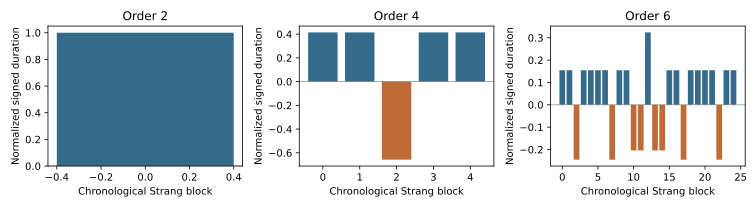

[(2, 1, 0), (4, 5, 1), (6, 25, 8)]

In [2]:
display(SVG(filename=str(data/"signed-substeps.svg")))
[(order, len(su.normalized_leaves(order)), sum(leaf.binary64<0 for leaf in su.normalized_leaves(order))) for order in (2,4,6)]

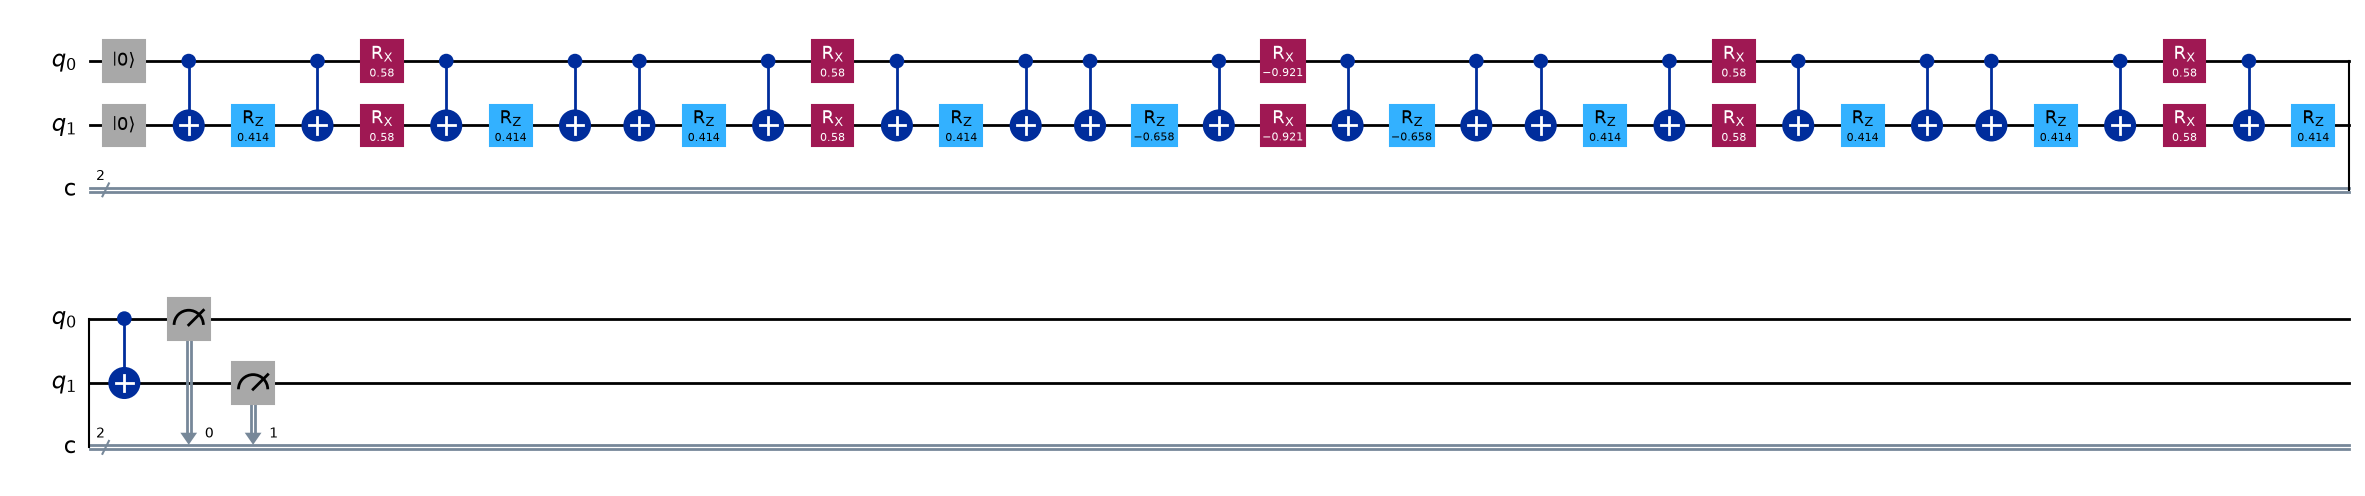

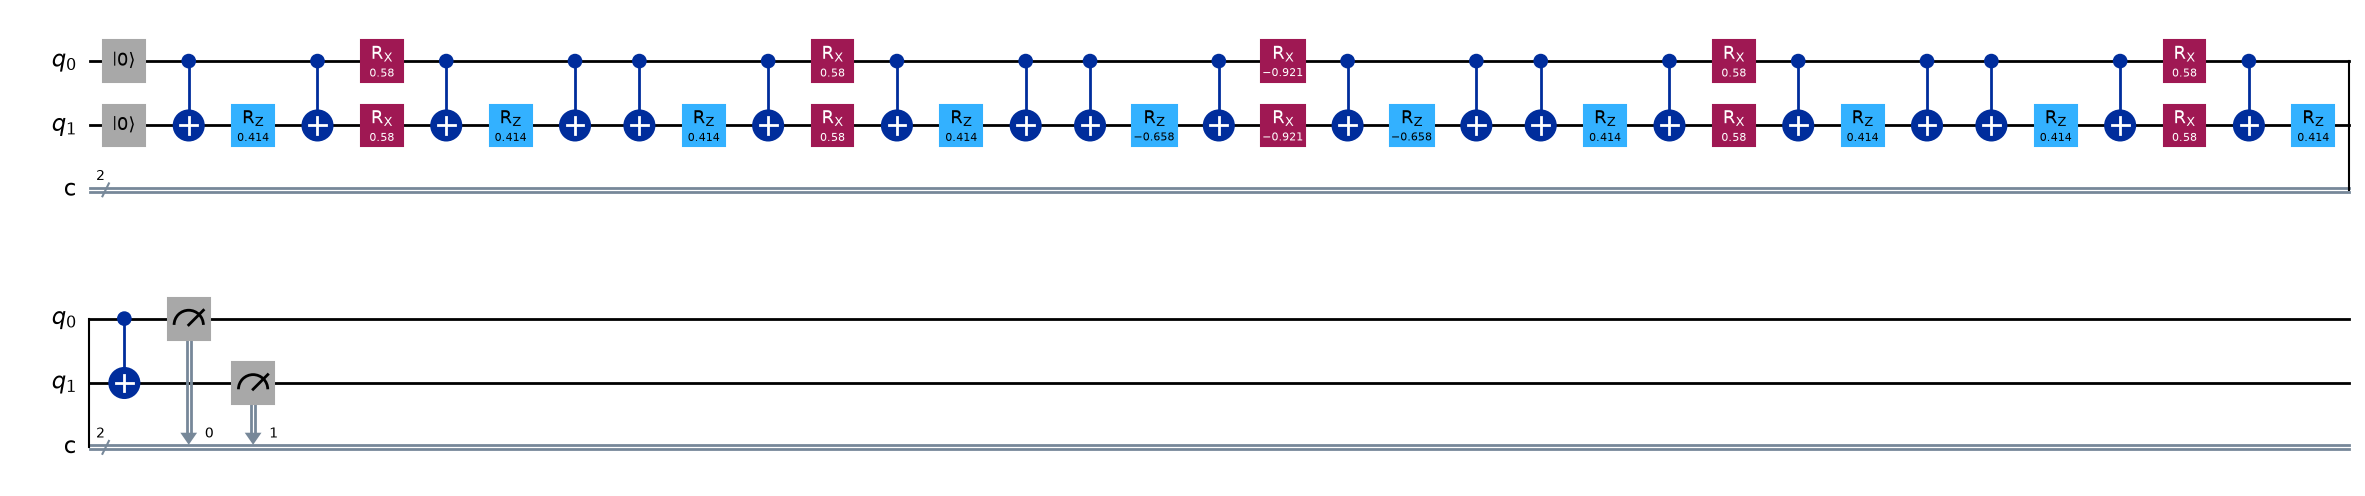

In [3]:
chain=su.SpinChain(2)
su.suzuki_circuit(chain,"1",1,4,measure=True).draw(output="mpl",fold=35)

## Independent matrix and package references

The matrix-exponential target, separate dense group product and pinned Qiskit implementation are distinct numerical references. The one-spin hZ=0 case is a commuting limit, not an asymptotic convergence fit.

In [4]:
check=su.compare_case(su.SpinChain(3),"1",2,6)
assert check["source_to_independent_dense_product_operator_error"] < 1e-10
assert check["source_to_qiskit_suzuki_operator_error"] < 1e-10
check

{'qubits': 3,
 'order': 6,
 'repetitions': 2,
 'time_exact': '1',
 'source_to_independent_dense_product_operator_error': 1.4098618399871415e-14,
 'source_to_qiskit_suzuki_operator_error': 1.1211061525235125e-15,
 'reset_prefix_density_error': 2.0995382881486674e-15,
 'operator_error_vs_exact_evolution': 1.0138031819359061e-05,
 'state_vector_error_vs_exact_evolution': 9.092421831416716e-06,
 'state_infidelity': 7.297051851651304e-11,
 'circuit_z0': 0.4042537844329206,
 'exact_z0': 0.40425585728735475,
 'observable_bias': 2.07285443415417e-06,
 'qiskit_reference_primitive_counts': {'rzz': 200, 'rx': 150},
 'qiskit_reference_grouping': 'Explicit nonempty commuting[A,B] groups; zero blocks omitted as a declared commuting-limit shortcut; source retains its S2 template.',
 'verified_tolerance': 1e-10,
 'formal_certificate': False,
 'scope': 'Bounded ideal numerical circuit/product/matrix-exponential comparisons; source parameter enclosures do not certify the large-system splitting error or 

,qubits,order,repetitions,source_operations,operator_error,observable_bias
0,1,2,1,3,1.110223e-16,1.665335e-16
1,1,2,2,4,2.220446e-16,5.551115e-17
2,1,2,4,6,2.220446e-16,5.551115e-17
3,1,2,8,10,5.113189e-16,3.330669e-16
4,1,4,1,7,3.592757e-16,2.220446e-16
5,1,4,2,12,3.592757e-16,0.000000e+00
6,1,4,4,22,6.661338e-16,1.110223e-16
7,1,4,8,42,2.075207e-15,2.775558e-16
8,1,6,1,27,1.254067e-15,6.661338e-16
9,1,6,2,52,1.604675e-15,2.775558e-16


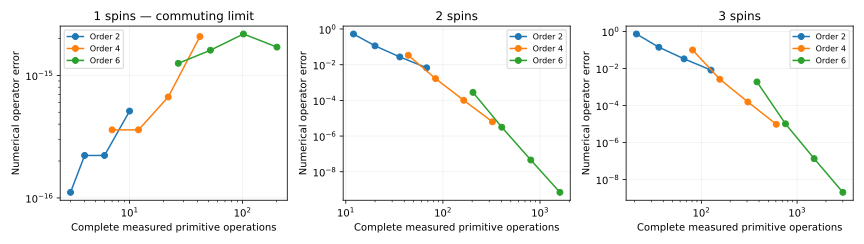

In [5]:
summary=pd.read_csv(data/"summary.csv")
display(summary[["qubits","order","repetitions","source_operations","operator_error","observable_bias"]])
display(SVG(filename=str(data/"error-vs-work.svg")))

## Coefficient and scalar rounding scope

Exact dyadic root enclosures and binary64 scalar conversion bounds compare actual source parameters with ideal Suzuki coefficients. They do not certify the splitting error relative to exact evolution, or a physical implementation.

In [6]:
rounding=su.parameter_rounding(su.SpinChain(3),"1",8,6)
{k: rounding[k] for k in ["normalized_signed_sum_exact_binary64","normalized_signed_sum_defect_exact","actual_absolute_substep_time_sum_exact","coefficient_approximation_operator_bound_exact","gate_angle_conversion_operator_bound_exact","total_source_parameter_operator_bound_upper_float"]}

{'normalized_signed_sum_exact_binary64': '9007199254740991/9007199254740992',
 'normalized_signed_sum_defect_exact': '1/9007199254740992',
 'actual_absolute_substep_time_sum_exact': '41397242223795171/9007199254740992',
 'coefficient_approximation_operator_bound_exact': '611869003280005946089180955933703776815821310055019691893365352630569416268374051164970046921131806986864049180332234450671239076740370305273782906261274861999844417918668957622607590581050862081/477401547373183216186404024244969984668294802330436979597033416846502951863529329610562058897418297891225878892410576011371206164478517677394534098839756837850176674048741983072596859380354559253782544504586240',
 'gate_angle_conversion_operator_bound_exact': '21/45035996273704960',
 'total_source_parameter_operator_bound_upper_float': 1.7479589825869562e-15}

## Larger generator and independent simulator guard

The 32-wire circuit below is generated without a statevector or matrix. Dense methods separately reject widths above three spins.

In [7]:
large=su.suzuki_circuit(su.SpinChain(32),"1",1,6,measure=True)
try:
    su.compare_case(su.SpinChain(32),"1",1,6)
except ValueError:
    print("Dense reference correctly refused the32-wire request.")
large.num_qubits, dict(large.count_ops()), large.depth()

Dense reference correctly refused the32-wire request.


(32, {'cx': 3100, 'rz': 1550, 'rx': 800, 'reset': 32, 'measure': 32}, 4677)

## Optional local controls

The static site uses saved outputs. A local or Binder kernel can run the bounded controls below.

In [8]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    @widgets.interact(order=widgets.Dropdown(options=[2,4,6],value=4),repetitions=widgets.IntSlider(value=1,min=1,max=8))
    def explore(order,repetitions):
        display(su.compare_case(su.SpinChain(2),"1",repetitions,order))
else:
    print("Static build: optional live controls omitted.")

Static build: optional live controls omitted.


## Resource and verification boundary

All complete source gates, initial resets/preparation and final readouts are counted. Repeated observable trials are an analytic workload proposal, not executed shots. Negative angles retain their gate costs. Factories, routed schedules, physical errors, certified synthesis and a Lean/Rocq implementation proof remain planned.